# One full plate of an optical pooled screen

The [optical pooled screens](optical_pooled_screens.ipynb) case study worked on a thin slice of the Aconcagua screen:
about a thousand genes, a few cells per guide, across all eight plates. Here we take one whole plate instead, every cell
of every guide, interphase and mitotic, and do the aggregation ourselves.

The cells are reduced two ways, side by side:

- **Guide route.** cells → one profile per guide per well → one profile per guide. A gene is called from its guides.
- **Pooled route.** cells → one profile per gene per well, pooling every cell of the gene's guides → one profile per gene.
  A gene is called from its pooled profile.

Each analysis then runs on both: hit calling against the unexpressed-gene null, the channel fingerprints of hits,
whether a gene's guides agree, and the gene landscape against CORUM and the published brieflow landscape.

In [1]:
import os
import time
import warnings

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score

import mantispy as mt

warnings.filterwarnings("ignore")
sc.settings.verbosity = 0
plt.rcParams["figure.dpi"] = 110
SEED = 0
CELLS = os.environ.get("OPS_CELLS", "aconcagua_plate1_cells.h5ad")
T0 = time.time()


def lap(what):
    print(f"[{time.time() - T0:6.0f}s] {what}")

## The plate

Plate 1 of Aconcagua, extracted in full from the screen's public `cell_data.parquet` and converted from brieflow's
feature names to mantispy's. Each well of an optical pooled screen carries the whole library, so one plate holds every
guide, with its wells as replicates.

In [2]:
cells = ad.read_h5ad(CELLS)
obs = cells.obs
ntc = obs["Metadata_Control_Type"] == "negcon"
summary = {
    "cells": cells.n_obs,
    "features": cells.n_vars,
    "wells": obs["Metadata_Well"].nunique(),
    "guides": obs["Metadata_Guide"].nunique(),
    "non-targeting guides": obs.loc[ntc, "Metadata_Guide"].nunique(),
    "genes": obs.loc[~ntc, "Metadata_Gene"].nunique(),
    "mitotic share": round(float(obs["Metadata_Mitotic"].mean()), 3),
}
lap("loaded")
pd.Series(summary)

[    44s] loaded


cells                   4524177.000
features                   1483.000
wells                         6.000
guides                    20435.000
non-targeting guides        250.000
genes                      5049.000
mitotic share                 0.026
dtype: float64

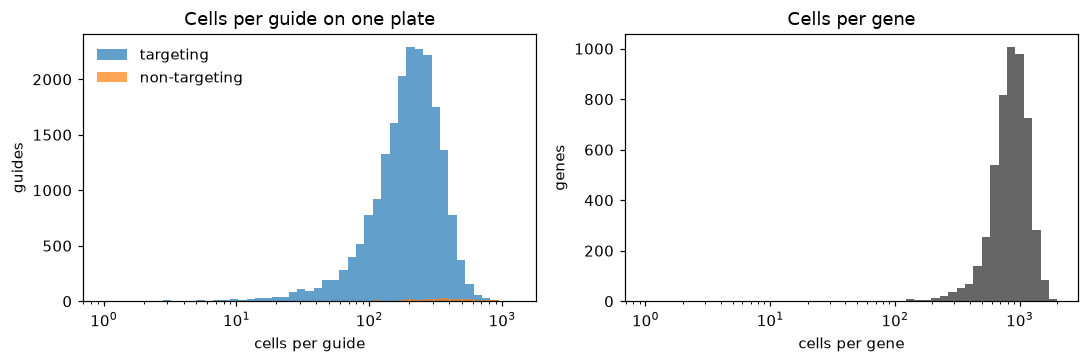

median cells per targeting guide 206, non-targeting 372, per gene 867


In [3]:
per_guide = obs.groupby("Metadata_Guide", observed=True).size()
guide_ntc = obs.groupby("Metadata_Guide", observed=True)["Metadata_Control_Type"].first() == "negcon"
per_gene = obs[~ntc].groupby("Metadata_Gene", observed=True).size()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.logspace(0, np.log10(per_guide.max() + 1), 50)
axes[0].hist(per_guide[~guide_ntc], bins=bins, alpha=0.7, label="targeting")
axes[0].hist(per_guide[guide_ntc], bins=bins, alpha=0.7, label="non-targeting")
axes[0].set(xscale="log", xlabel="cells per guide", ylabel="guides", title="Cells per guide on one plate")
axes[0].legend(frameon=False)
axes[1].hist(per_gene, bins=np.logspace(0, np.log10(per_gene.max() + 1), 50), color="0.4")
axes[1].set(xscale="log", xlabel="cells per gene", ylabel="genes", title="Cells per gene")
fig.tight_layout()
plt.show()
print(
    f"median cells per targeting guide {per_guide[~guide_ntc].median():.0f}, "
    f"non-targeting {per_guide[guide_ntc].median():.0f}, per gene {per_gene.median():.0f}"
)

## From cells to guides and genes

First the cells are normalized against the non-targeting cells of their own well
({func}`~mantispy.pp.normalize`, robust z-scores), so every well is on its own control scale before anything is pooled.

The non-targeting guides need roles. The guide route scores each guide against one set of them
({func}`~mantispy.tl.guide_activity`) and builds its null from a second, disjoint set
({func}`~mantispy.tl.aggregate_guides`); the rest are grouped four at a time into pseudo-genes that should never be
called. The pooled route groups all non-targeting guides four at a time into pseudo-genes, which are its controls.

In [4]:
mt.pp.normalize(cells, by=["Metadata_Plate", "Metadata_Well"], reference="negcon")
lap("normalized")

ntc_guides = np.sort(obs.loc[ntc, "Metadata_Guide"].astype(str).unique())
roll = np.random.default_rng(SEED).permutation(ntc_guides)
role = dict.fromkeys(roll[:100], "ntc_scale") | dict.fromkeys(roll[100:200], "nontargeting")
role |= {g: f"PSEUDO{i // 4:02d}" for i, g in enumerate(roll[200 : 200 + 4 * ((len(roll) - 200) // 4)])}
unit = {g: f"NTC{i // 4:02d}" for i, g in enumerate(roll[: 4 * (len(roll) // 4)])}

guide = obs["Metadata_Guide"].astype(str)
gene = obs["Metadata_Gene"].astype(str)
obs["Analysis_Group"] = pd.Categorical(np.where(guide.map(role).notna(), guide.map(role), gene))
obs["Gene_Unit"] = pd.Categorical(np.where(guide.map(unit).notna(), guide.map(unit), np.where(ntc, "dropped", gene)))

[   105s] normalized


Two aggregations of the same normalized cells, both medians ({func}`~mantispy.tl.aggregate`). A guide or gene needs five
cells in a well for that well to count.

In [5]:
guide_well = mt.tl.aggregate(
    cells, by=("Metadata_Plate", "Metadata_Well", "Metadata_Guide"), func="median", min_cells=5
)
lap(f"guide x well: {guide_well.n_obs}")
keep = obs["Gene_Unit"].astype(str) != "dropped"
gene_well = mt.tl.aggregate(
    cells[keep.to_numpy()], by=("Metadata_Plate", "Metadata_Well", "Gene_Unit"), func="median", min_cells=5
)
lap(f"gene x well: {gene_well.n_obs}")

# Mitotic share per guide and per gene, from the cells, before the cell table is dropped.
mito_guide = obs.groupby("Metadata_Guide", observed=True)["Metadata_Mitotic"].mean()
mito_gene = obs[keep.to_numpy()].groupby("Gene_Unit", observed=True)["Metadata_Mitotic"].mean()
example_cells = cells[obs["Metadata_Gene"].astype(str).isin(["HAUS6", "TUBB", "H2AX", "CFL1"]).to_numpy()].copy()
degenerate = cells.var["degenerate_scale"].to_numpy()
del cells

[   145s] guide x well: 118470


[   213s] gene x well: 30665


Features are chosen once, on the guide profiles ({func}`~mantispy.pp.feature_select`), and both routes keep the same set,
so the routes differ only in how cells are pooled.

In [6]:
guide_well.X = np.nan_to_num(guide_well.X)
gene_well.X = np.nan_to_num(gene_well.X)
mt.pp.feature_select(guide_well)
chosen = guide_well.var["selected"].to_numpy() & ~degenerate
guide_well = guide_well[:, chosen].copy()
gene_well = gene_well[:, chosen].copy()

guides = mt.tl.aggregate(guide_well, by=("Metadata_Guide",), func="median", min_cells=1)
genes = mt.tl.aggregate(gene_well, by=("Gene_Unit",), func="median", min_cells=1)
for a in (guide_well, gene_well, guides, genes):
    a.X = np.nan_to_num(a.X)
lap("features selected")
pd.DataFrame(
    {
        "rows": [guide_well.n_obs, guides.n_obs, gene_well.n_obs, genes.n_obs],
        "median cells per row": [
            int(a.obs["Metadata_CellCount"].median()) for a in (guide_well, guides, gene_well, genes)
        ],
    },
    index=["guide x well", "guide", "gene x well (pooled)", "gene (pooled)"],
).assign(features=int(chosen.sum()))

[   230s] features selected


,rows,median cells per row,features
guide x well,118470,34,1120
guide,20373,207,1120
gene x well (pooled),30665,143,1120
gene (pooled),5111,869,1120


## Hit calling, guide route

As in the thin-slice case study: each guide is scored against the `ntc_scale` non-targeting guides, a gene's guides are
combined with Stouffer's method against a null drawn from the disjoint `nontargeting` set, and then the call is
calibrated against the genes HeLa does not express. Those genes are cut but have nothing to lose, so they set the null for
*beyond cutting* ({func}`~mantispy.tl.empirical_fdr`).

In [7]:
unexpressed = mt.io.unexpressed_genes(mt.ds.depmap_expression(), "ACH-001086")
POSCON = ["H2AX", "ECT2", "TUBB", "CFL1"]

sc.pp.pca(guides, n_comps=50, random_state=SEED)
mt.tl.guide_activity(guides, reference="ntc_scale", group="Analysis_Group", use_rep="X_pca")
mt.tl.aggregate_guides(
    guides,
    score="guide_activity",
    guide="Metadata_Guide",
    gene="Analysis_Group",
    control="nontargeting",
    n_null=20000,
    seed=SEED,
)
g_calls = pd.DataFrame(guides.uns["mantispy"]["gene_aggregation"]).set_index("group")
g_calls = g_calls[~g_calls.index.str.startswith(("PSEUDO", "ntc_scale", "nontargeting"))]
pseudo = pd.DataFrame(guides.uns["mantispy"]["gene_aggregation"]).set_index("group")
pseudo = pseudo[pseudo.index.str.startswith("PSEUDO")]


def beyond_cutting(scores):
    table = ad.AnnData(obs=pd.DataFrame({"gene": scores.index, "score": scores.to_numpy()}, index=scores.index))
    mt.tl.empirical_fdr(
        table,
        control_genes=sorted(set(scores.index) & unexpressed),
        score="score",
        group="gene",
        alpha=0.05,
        criterion="q",
    )
    return pd.DataFrame(table.uns["mantispy"]["empirical_fdr"]).set_index("group")["is_hit"].reindex(scores.index)


g_calls["beyond_cutting"] = beyond_cutting(g_calls["statistic"]).astype(bool)
g_calls["unexpressed"] = g_calls.index.isin(unexpressed)
lap("guide-route calls")
print(f"pseudo-genes called vs non-targeting: {int(pseudo['is_hit'].sum())} of {len(pseudo)}")
print(
    "positive controls:",
    g_calls.loc[[g for g in POSCON if g in g_calls.index], ["statistic", "is_hit", "beyond_cutting"]].to_dict("index"),
)

[   244s] guide-route calls
pseudo-genes called vs non-targeting: 0 of 12
positive controls: {'H2AX': {'statistic': 3.5876636227629035, 'is_hit': True, 'beyond_cutting': True}, 'ECT2': {'statistic': 3.100680219633884, 'is_hit': True, 'beyond_cutting': False}, 'TUBB': {'statistic': 3.1902381512284785, 'is_hit': True, 'beyond_cutting': False}, 'CFL1': {'statistic': 3.5682518743321543, 'is_hit': True, 'beyond_cutting': True}}


## Hit calling, pooled route

A pooled gene profile has no guides to combine, so its call is the phenotypic activity of its well replicates: mean
average precision of retrieving the gene's wells against the non-targeting pseudo-gene wells
({func}`~mantispy.tl.map`, `mode="activity"`). The same unexpressed-gene calibration follows. For comparison the same
activity is computed at the guide route's finest grain, guide × well.

In [8]:
sc.pp.pca(gene_well, n_comps=50, random_state=SEED)
mt.tl.map(
    gene_well,
    mode="activity",
    label="Gene_Unit",
    reference="negcon",
    use_rep="X_pca",
    null_size=20000,
    n_jobs=os.cpu_count(),
    key_added="activity",
)
p_map = gene_well.uns["mantispy"]["activity"].set_index("Gene_Unit")
p_calls = p_map[~p_map.index.str.startswith("NTC")].copy()
p_calls["beyond_cutting"] = beyond_cutting(p_calls["score"]).astype(bool)
p_calls["unexpressed"] = p_calls.index.isin(unexpressed)
lap("pooled-route calls")

sc.pp.pca(guide_well, n_comps=50, random_state=SEED)
mt.tl.map(
    guide_well,
    mode="activity",
    label="Metadata_Guide",
    reference="negcon",
    use_rep="X_pca",
    null_size=20000,
    n_jobs=os.cpu_count(),
    key_added="activity",
)
gw_map = guide_well.uns["mantispy"]["activity"].set_index("Metadata_Guide")
guide_gene = guides.obs.set_index("Metadata_Guide")["Metadata_Gene"].astype(str)
gw_map["gene"] = guide_gene.reindex(gw_map.index).to_numpy()
lap("guide x well mAP")
print(
    "positive controls:",
    p_calls.loc[[g for g in POSCON if g in p_calls.index], ["score", "is_significant", "beyond_cutting"]].to_dict(
        "index"
    ),
)

[   388s] pooled-route calls


Excluding 86 rows with missing AP/no positive pairs and 0 rows with missing group keys


[  1412s] guide x well mAP
positive controls: {'H2AX': {'score': 0.901400966183575, 'is_significant': True, 'beyond_cutting': True}, 'ECT2': {'score': 0.033767424162226334, 'is_significant': False, 'beyond_cutting': False}, 'TUBB': {'score': 0.9944444444444445, 'is_significant': True, 'beyond_cutting': True}, 'CFL1': {'score': 1.0, 'is_significant': True, 'beyond_cutting': True}}


## The two routes side by side

Call rates against the non-targeting null and beyond cutting. The unexpressed genes are the honest check: whatever rate
they get called at is the rate at which a route calls cutting alone.

vs non-targeting  beyond cutting  genes
             kind                                                
guide route  expressed               0.669           0.025   4685
             unexpressed             0.560           0.000    364
pooled route expressed               0.428           0.079   4685
             unexpressed             0.305           0.000    364

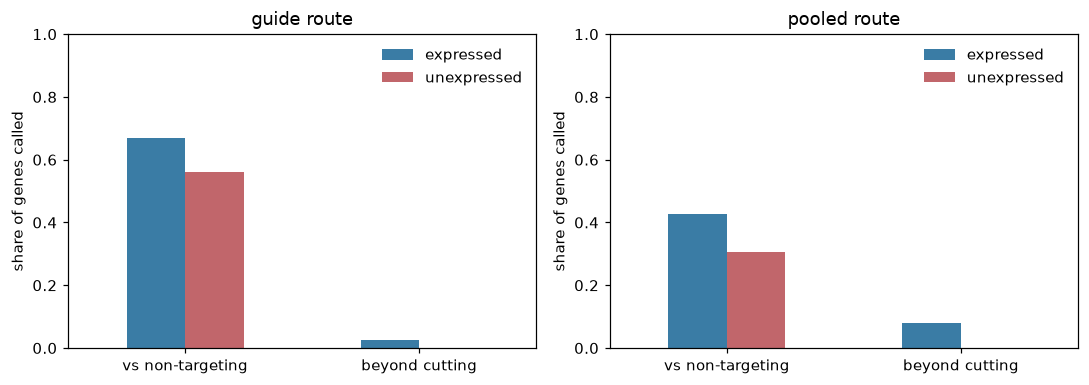

In [9]:
def rates(calls, hit):
    calls = calls.assign(kind=np.where(calls["unexpressed"], "unexpressed", "expressed"))
    return calls.groupby("kind").agg(
        **{"vs non-targeting": (hit, "mean"), "beyond cutting": ("beyond_cutting", "mean"), "genes": (hit, "size")}
    )


both = pd.concat({"guide route": rates(g_calls, "is_hit"), "pooled route": rates(p_calls, "is_significant")})
display(both.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (name, table) in zip(axes, both.groupby(level=0)):
    t = table.droplevel(0)[["vs non-targeting", "beyond cutting"]]
    t.T.plot.bar(ax=ax, rot=0, color=["#3a7ca5", "#c1666b"])
    ax.set(title=name, ylabel="share of genes called", ylim=(0, 1))
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

genes in both: 5049; beyond-cutting hits guide route 115, pooled 371, both 72
Spearman between the routes' gene scores: 0.56


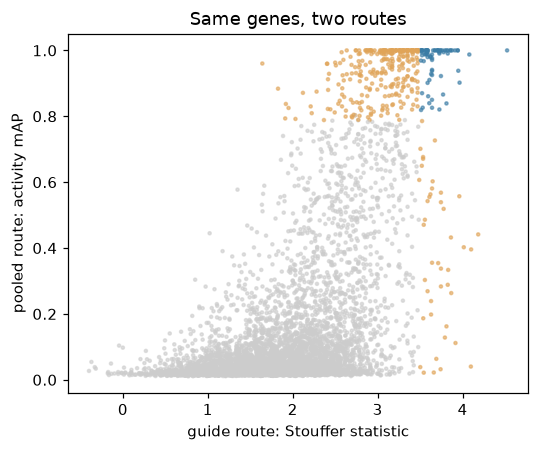

In [10]:
shared = g_calls.index.intersection(p_calls.index)
gh = set(shared[g_calls.loc[shared, "beyond_cutting"].to_numpy()])
ph = set(shared[p_calls.loc[shared, "beyond_cutting"].to_numpy()])
rho = spearmanr(g_calls.loc[shared, "statistic"], p_calls.loc[shared, "score"]).statistic
print(f"genes in both: {len(shared)}; beyond-cutting hits guide route {len(gh)}, pooled {len(ph)}, both {len(gh & ph)}")
print(f"Spearman between the routes' gene scores: {rho:.2f}")

fig, ax = plt.subplots(figsize=(5, 4.2))
col = np.where([g in gh & ph for g in shared], "#3a7ca5", np.where([g in gh | ph for g in shared], "#e0a458", "0.8"))
ax.scatter(g_calls.loc[shared, "statistic"], p_calls.loc[shared, "score"], s=4, c=col, alpha=0.6)
ax.set(xlabel="guide route: Stouffer statistic", ylabel="pooled route: activity mAP", title="Same genes, two routes")
fig.tight_layout()
plt.show()

## Do a gene's guides agree?

The guide route can ask something the pooled route cannot: whether a gene's guides tell the same story. Correlating the
profiles of every pair of guides of a gene, against random pairs of guides and against pairs within a non-targeting
pseudo-gene, shows how much of a gene's signal its guides share. Fisher's method, which fires on a single strong guide,
against Stouffer's, which needs the guides to agree, counts the genes carried by one guide.

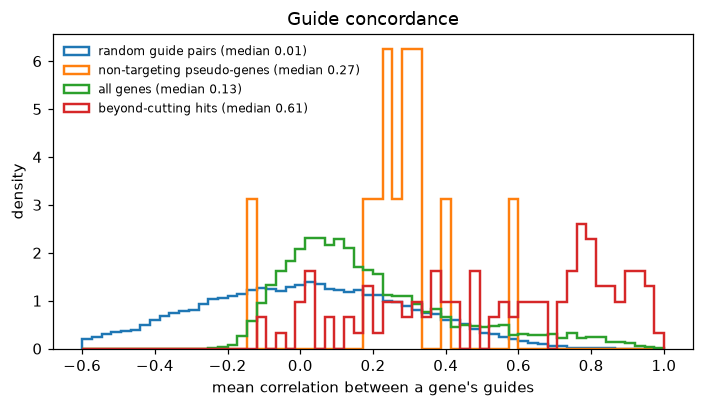

called vs non-targeting: Stouffer 3336, Fisher 2266, Fisher-only (one guide carries it) 0


In [11]:
Z = guides.obsm["X_pca"]
Z = (Z - Z.mean(1, keepdims=True)) / Z.std(1, keepdims=True)
grp = guides.obs["Analysis_Group"].astype(str).to_numpy()
active_genes = {g for g in g_calls.index[g_calls["beyond_cutting"]]}


def within(names):
    out = []
    for g in names:
        idx = np.flatnonzero(grp == g)
        if len(idx) >= 2:
            c = Z[idx] @ Z[idx].T / Z.shape[1]
            out.append(c[np.triu_indices(len(idx), 1)].mean())
    return np.array(out)


rng = np.random.default_rng(SEED)
i, j = rng.integers(0, len(Z), 20000), rng.integers(0, len(Z), 20000)
random_pairs = (Z[i] * Z[j]).mean(1)
conc = {
    "random guide pairs": random_pairs,
    "non-targeting pseudo-genes": within(sorted({g for g in grp if g.startswith("PSEUDO")})),
    "all genes": within(sorted(set(g_calls.index))),
    "beyond-cutting hits": within(sorted(active_genes)),
}
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, v in conc.items():
    ax.hist(
        v, bins=60, range=(-0.6, 1), density=True, histtype="step", lw=1.6, label=f"{name} (median {np.median(v):.2f})"
    )
ax.set(xlabel="mean correlation between a gene's guides", ylabel="density", title="Guide concordance")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

fisher = guides.copy()
mt.tl.aggregate_guides(
    fisher,
    score="guide_activity",
    guide="Metadata_Guide",
    gene="Analysis_Group",
    control="nontargeting",
    method="fisher",
    n_null=20000,
    seed=SEED,
)
ft = pd.DataFrame(fisher.uns["mantispy"]["gene_aggregation"]).set_index("group").reindex(g_calls.index)
print(
    f"called vs non-targeting: Stouffer {int(g_calls['is_hit'].sum())}, Fisher {int(ft['is_hit'].sum())}, "
    f"Fisher-only (one guide carries it) {int((ft['is_hit'] & ~g_calls['is_hit']).sum())}"
)

In [12]:
# Guide x well activity: how many of a hit gene's guides are themselves active, at the guide's finest grain.
gw = gw_map[gw_map["gene"].isin(g_calls.index)]
n_active = gw.groupby("gene")["is_significant"].sum()
n_guides = gw.groupby("gene").size()
tab = n_active.reindex(sorted(active_genes)).dropna().astype(int).value_counts().sort_index()
display(tab.rename_axis("active guides of a beyond-cutting gene").to_frame("genes").T)
print(f"guide x well activity: {int(gw['is_significant'].sum())} of {len(gw)} targeting guides active")

active guides of a beyond-cutting gene,0,1,2,3,4
genes,16,19,21,29,30


guide x well activity: 2340 of 20037 targeting guides active


## What the hits look like

The fingerprint of a hit is which channels it moves. The same differential test
({func}`~mantispy.tl.differential_features`) runs once on guide × well profiles and once on pooled gene × well profiles,
for a handful of known biology: replication stress, the spindle, adhesion, the proteasome and the spliceosome, plus the
positive controls.

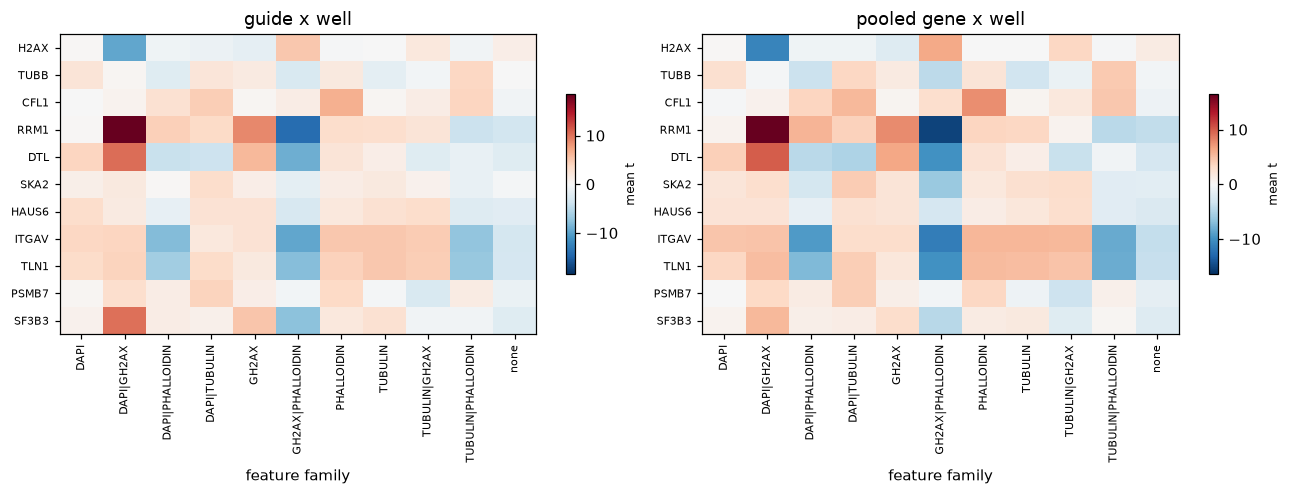

In [13]:
EXAMPLES = ["H2AX", "TUBB", "CFL1", "RRM1", "DTL", "SKA2", "HAUS6", "ITGAV", "TLN1", "PSMB7", "SF3B3"]


def fingerprint(profiles, title, ax):
    g = profiles.obs["Metadata_Gene"].astype(str)
    sub = profiles[(g.isin(EXAMPLES) | (profiles.obs["Metadata_Control_Type"] == "negcon")).to_numpy()].copy()
    mt.tl.differential_features(sub, groupby="Metadata_Gene", reference="negcon", block="Metadata_Well")
    sig = mt.tl.feature_signature(sub, key="differential", by=("channel",), statistic="t")
    sig = sig[[x for x in EXAMPLES if x in sig.obs_names]].copy()
    mt.pl.feature_signature(sig, top=sig.n_vars, cluster=False, ax=ax)
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
fingerprint(guide_well, "guide x well", axes[0])
fingerprint(gene_well, "pooled gene x well", axes[1])
fig.tight_layout()
plt.show()

All cells were kept, mitotic ones included, so a knockout that arrests cells in mitosis shows it as a share. The genes
with the largest mitotic share, by pooled cells, against the non-targeting baseline, with the spread of their guides.

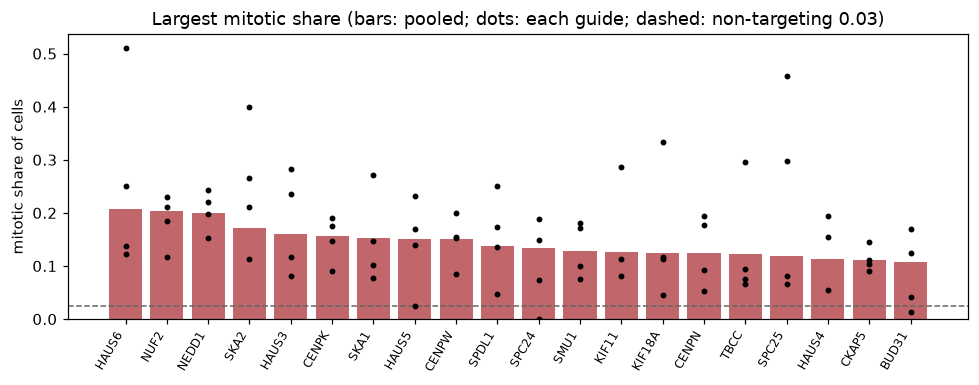

In [14]:
base = float(mito_gene[mito_gene.index.str.startswith("NTC")].median())
top = mito_gene[~mito_gene.index.str.startswith("NTC")].sort_values(ascending=False).head(20)
per_guide_share = pd.DataFrame({"share": mito_guide, "gene": guide_gene.reindex(mito_guide.index)})
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(top)), top.to_numpy(), color="#c1666b")
for k, g in enumerate(top.index):
    s = per_guide_share.loc[per_guide_share["gene"] == g, "share"]
    ax.scatter(np.full(len(s), k), s, color="k", s=8, zorder=3)
ax.axhline(base, color="0.4", ls="--", lw=1)
ax.set_xticks(range(len(top)), top.index, rotation=60, ha="right", fontsize=8)
ax.set(
    ylabel="mitotic share of cells",
    title=f"Largest mitotic share (bars: pooled; dots: each guide; dashed: non-targeting {base:.2f})",
)
fig.tight_layout()
plt.show()

In [15]:
example_cells.obs["phase"] = np.where(example_cells.obs["Metadata_Mitotic"] > 0, "mitotic", "interphase")
share = example_cells.obs.groupby(["Metadata_Gene", "Metadata_Guide"], observed=True)["Metadata_Mitotic"].agg(
    ["mean", "size"]
)
share.round(3)

mean  size
Metadata_Gene Metadata_Guide             
CFL1          GCGTAAGTCTT     0.013   149
              TCTTGACAAAG     0.014   208
              TGATGCAACCT     0.037   327
              TTGCATCATAG     0.024   250
H2AX          AAGAAGACCAG     0.069   306
              CCGCGGCAAGA     0.011   174
              GCCGGTGTACA     0.011   177
              TTCGCGTCTTC     0.033   211
HAUS6         AAATTATATGA     0.511    45
              AACTTGAGATC     0.122    82
              ATGCATTTGTG     0.137   146
              CTGATTCCTTA     0.250    92
TUBB          CCCCACCGGCA     0.222     9
              CTGCATTCCAG     0.091   186
              GCTGACCACAC     0.102   147
              TGAGCTGGCCA     0.022    45

## The landscape, built from our own aggregation

The thin-slice case study borrowed the published brieflow landscape. Here the gene profiles are our own, from one plate.
Two gene tables go in: the guide route's (median of a gene's guide profiles) and the pooled route's. Each is tested for
CORUM complex coherence ({func}`~mantispy.tl.pathway_coherence`), clustered, and its clusters named by CORUM
({func}`~mantispy.tl.ora`). The published landscape runs through the same code as a reference.

In [16]:
published = ad.read_h5ad(
    pooch.retrieve(
        "https://ops-explorer-public.s3.amazonaws.com/aconcagua/aconcagua/visualizations/interphase/aggregated_data.h5ad",
        known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
        fname="brief_interphase.h5ad",
    )
)
pub = ad.AnnData(
    X=np.nan_to_num(np.asarray(published.X, dtype="float32")),
    obs=pd.DataFrame(
        {
            "Metadata_Gene": published.obs_names.astype(str),
            "cluster_published": published.obs["cluster_group_1"].astype(str).values,
        },
        index=published.obs_names.astype(str),
    ),
)

tg = guides[~guides.obs["Analysis_Group"].astype(str).str.match(r"^(PSEUDO|ntc_scale|nontargeting)")].copy()
via_guides = mt.tl.aggregate(tg, by=("Metadata_Gene",), func="median", min_cells=1)
via_guides.obs_names = via_guides.obs["Metadata_Gene"].astype(str).to_numpy()
pooled = genes[~genes.obs["Gene_Unit"].astype(str).str.startswith("NTC")].copy()
pooled.obs_names = pooled.obs["Gene_Unit"].astype(str).to_numpy()
pooled.obs["Metadata_Gene"] = pooled.obs_names

# Same gene universe in every table: genes measured here and in the published landscape.
universe = sorted(set(via_guides.obs_names) & set(pooled.obs_names) & set(pub.obs_names))
tables = {
    "guide route": via_guides[universe].copy(),
    "pooled route": pooled[universe].copy(),
    "published": pub[universe].copy(),
}
for t in tables.values():
    t.X = np.nan_to_num(np.asarray(t.X, dtype="float32"))
print(f"{len(universe)} genes in all three tables")
lap("gene tables")

5049 genes in all three tables
[  1446s] gene tables


In [17]:
corum = mt.ds.corum()
coh = {}
for name, t in tables.items():
    mt.tl.pathway_coherence(
        t, corum, gene_key="Metadata_Gene", min_genes=4, n_permutations=1000, seed=SEED, metric="pearson"
    )
    pc = pd.DataFrame(t.uns["mantispy"]["pathway_coherence"])
    coh[name] = {
        "complexes tested": len(pc),
        "coherent at q < 0.05": int((pc["qvalue"] < 0.05).sum()),
        "median coherence": round(float(pc["coherence"].median()), 3),
    }
lap("coherence")
pd.DataFrame(coh).T

[  1495s] coherence


,complexes tested,coherent at q < 0.05,median coherence
guide route,430.0,130.0,0.270
pooled route,430.0,117.0,0.298
published,430.0,169.0,0.408


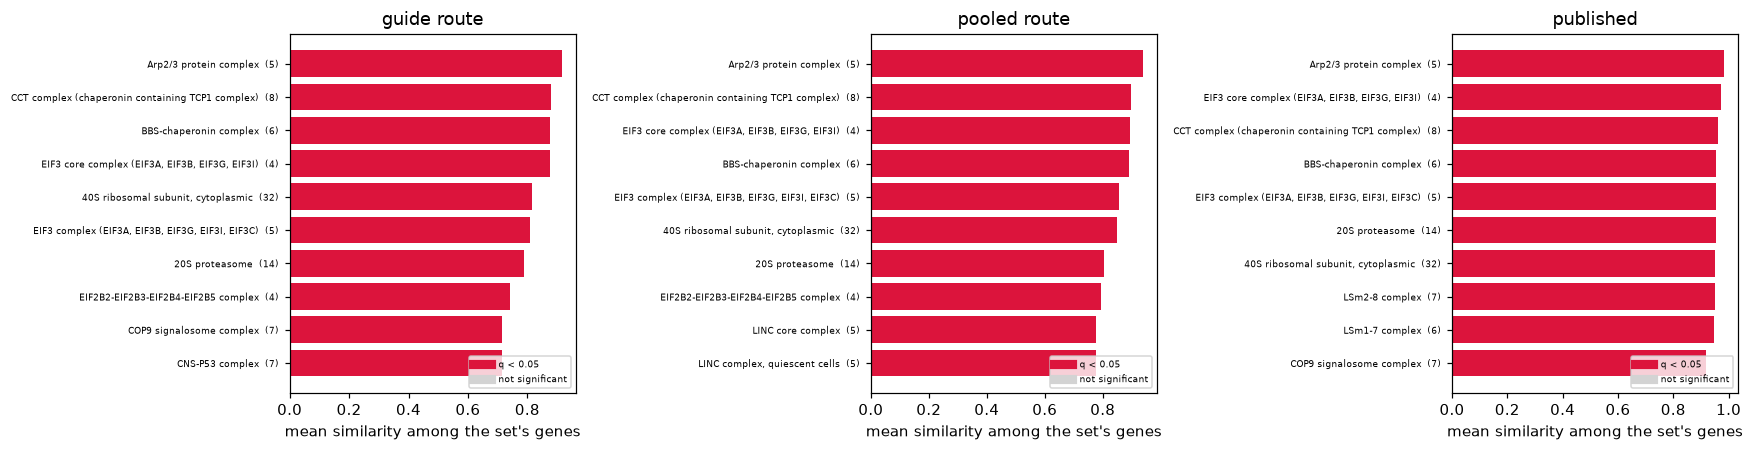

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, t) in zip(axes, tables.items()):
    mt.pl.pathway_coherence(t, top=10, ax=ax)
    ax.set_title(name)
fig.tight_layout()
plt.show()

## Agreement with the published landscape

Two checks that our aggregation of one plate recovers the published screen-wide landscape: how well each table's
gene-gene similarities rank like the published ones, and how well its clusters match the published clusters.

In [19]:
rng = np.random.default_rng(SEED)
pick = np.sort(rng.choice(len(universe), size=min(2000, len(universe)), replace=False))
iu = np.triu_indices(len(pick), 1)


def sims(t):
    X = np.asarray(t.X)[pick]
    return np.corrcoef(X)[iu]


ref = sims(tables["published"])
for name in ("guide route", "pooled route"):
    print(
        f"{name}: Spearman of gene-gene similarities with published {spearmanr(sims(tables[name]), ref).statistic:.3f}"
    )

for name, t in tables.items():
    sc.pp.pca(t, n_comps=min(50, t.n_vars - 1), random_state=SEED)
    sc.pp.neighbors(t, n_neighbors=15, random_state=SEED)
    sc.tl.leiden(t, resolution=2.0, random_state=SEED, key_added="cluster", flavor="igraph", n_iterations=2)
    sc.tl.umap(t, random_state=SEED)
pub_cl = tables["published"].obs["cluster_published"]
ari = {name: adjusted_rand_score(pub_cl, t.obs["cluster"]) for name, t in tables.items()}
print("ARI with the published clusters:", {k: round(v, 3) for k, v in ari.items()})
lap("clusters")

guide route: Spearman of gene-gene similarities with published 0.547


pooled route: Spearman of gene-gene similarities with published 0.554


ARI with the published clusters: {'guide route': 0.037, 'pooled route': 0.038, 'published': 0.077}
[  1572s] clusters


In [20]:
named = {}
for name, t in tables.items():
    mt.tl.ora(t, groupby="cluster", net=corum, gene_key="Metadata_Gene", tmin=4, padj_by="group")
    ora = pd.DataFrame(t.uns["mantispy"]["ora"])
    best = ora[ora["odds_ratio"] > 0].sort_values("qvalue").groupby("group").head(1)
    named[name] = best[best["qvalue"] < 1e-3]
print(
    {
        k: f"{len(v)} of {t.obs['cluster'].nunique()} clusters named by a CORUM complex at q < 1e-3"
        for (k, v), t in zip(named.items(), tables.values())
    }
)
pd.concat(
    {
        k: v.sort_values("qvalue").head(8)[["group", "source", "qvalue"]].reset_index(drop=True)
        for k, v in named.items()
    },
    axis=1,
)

{'guide route': '10 of 27 clusters named by a CORUM complex at q < 1e-3', 'pooled route': '13 of 26 clusters named by a CORUM complex at q < 1e-3', 'published': '16 of 31 clusters named by a CORUM complex at q < 1e-3'}


guide route                                                   pooled route  \
        group                              source        qvalue        group   
0          25              PA700-20S-PA28 complex  5.895827e-58           23   
1          11  60S ribosomal subunit, cytoplasmic  3.805415e-51           25   
2          21  40S ribosomal subunit, cytoplasmic  6.455032e-45            9   
3          15                         Spliceosome  5.846776e-35            8   
4           3              Nup 107-160 subcomplex  1.392831e-10           24   
5           9                    Mediator complex  1.741671e-10            6   
6          10      RNA polymerase II core complex  3.437015e-07           13   
7          26                 Cohesin-SA2 complex  1.732365e-06           10   

                                                    published  \
                               source        qvalue     group   
0              PA700-20S-PA28 complex  1.372818e-59        30   
1                         Spliceosome  7.203189e-50         4   
2  40S ribosomal subunit, cytoplasmic  3.846622e-47         5   
3  60S ribosomal subunit, cytoplasmic  3.029562e-43        28   
4                    Mediator complex  1.126674e-21         7   
5              Nup 107-160 subcomplex  1.093638e-08        26   
6          RNA polymerase II (RNAPII)  1.756630e-07        24   
7                         COG complex  2.717622e-06        19   

                                                                   
                                             source        qvalue  
0                            PA700-20S-PA28 complex  2.968874e-53  
1                60S ribosomal subunit, cytoplasmic  2.757541e-52  
2                40S ribosomal subunit, cytoplasmic  3.844283e-52  
3                                       Spliceosome  1.242351e-40  
4  CCT complex (chaperonin containing TCP1 complex)  1.920071e-25  
5                                  Mediator complex  4.983781e-15  
6                        RNA polymerase II (RNAPII)  2.480899e-14  
7                          HAUS augmin-like complex  2.292140e-09

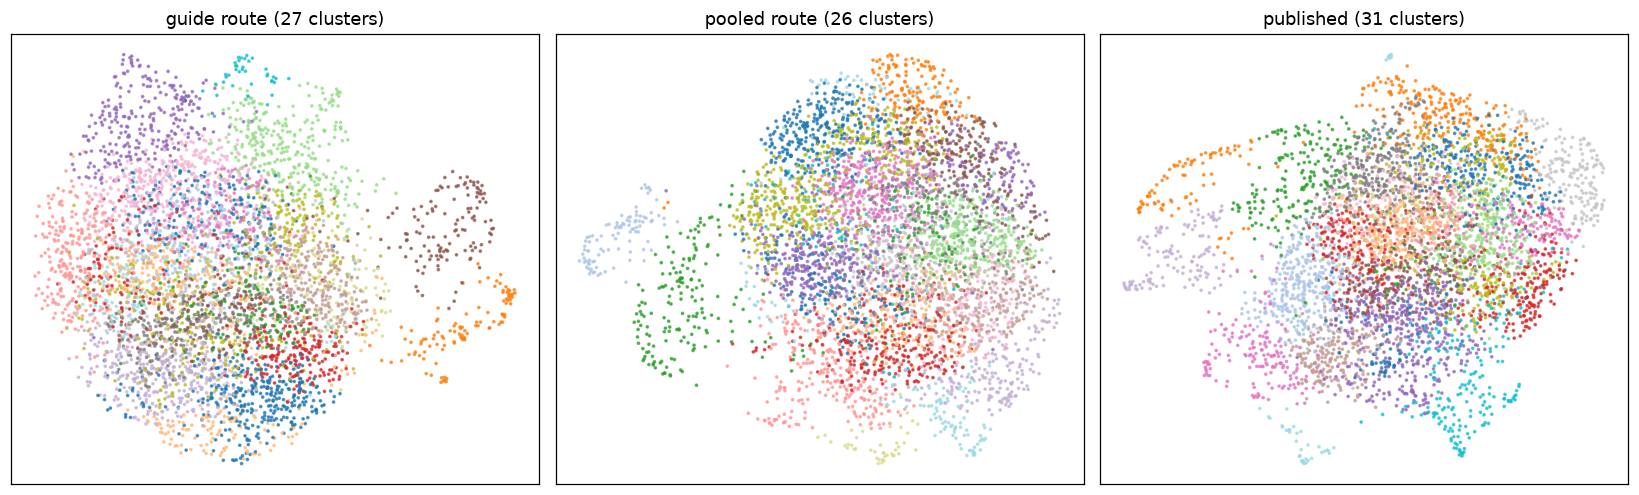

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (name, t) in zip(axes, tables.items()):
    u = t.obsm["X_umap"]
    ax.scatter(u[:, 0], u[:, 1], s=2, c=pd.factorize(t.obs["cluster"])[0], cmap="tab20", alpha=0.7)
    ax.set(title=f"{name} ({t.obs['cluster'].nunique()} clusters)", xticks=[], yticks=[])
fig.tight_layout()
plt.show()

## What to take away

The numbers above are from one plate of eight. The guide route and the pooled route are two ways to pool the same normalized
cells; the guide route keeps the guides apart until the call, which is what lets it test whether they agree, and the pooled
route spends every cell on one profile per gene.

In [22]:
lap("done")

[  1576s] done
